In [1]:
# !pip install opencv-python numpy scikit-image matplotlib pandas   # run once if needed
import cv2, glob, os, zipfile, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from skimage.metrics import peak_signal_noise_ratio as psnr, structural_similarity as ssim
from skimage.morphology import skeletonize
np.random.seed(0)

DOCX = ""   # e.g. "OPEN_ENDED_PROBLEM_10.docx"  (leave "" if images are already in dataset/)
os.makedirs("dataset", exist_ok=True)
if DOCX:
    with zipfile.ZipFile(DOCX) as z:
        for n in z.namelist():
            if n.startswith("word/media/"):
                open("dataset/" + os.path.basename(n), "wb").write(z.read(n))
paths = sorted(glob.glob("dataset/*"))
print(len(paths), "images found:", [os.path.basename(p) for p in paths])

5 images found: ['image1.png', 'image2.png', 'image3.png', 'image4.png', 'image5.png']


In [2]:
def dist(shape):
    r, c = shape
    u, v = np.meshgrid(np.arange(c) - c // 2, np.arange(r) - r // 2)
    return np.sqrt(u**2 + v**2)

def lowpass(kind, D, D0, n=2):
    if kind == "Ideal":       return (D <= D0).astype(float)
    if kind == "Butterworth": return 1 / (1 + (D / D0) ** (2 * n))
    return np.exp(-D**2 / (2 * D0**2))                     # Gaussian

def apply(img, H):                                          # FFT -> multiply by filter -> inverse FFT
    F = np.fft.fftshift(np.fft.fft2(img))
    return np.real(np.fft.ifft2(np.fft.ifftshift(F * H)))

def clip(x): return np.clip(x, 0, 255).astype(np.uint8)

In [3]:
D0, A = 40, 2.0          # low-pass cutoff and high-boost factor (change to experiment)

def process(img):
    img = cv2.medianBlur(img, 3)
    f = img.astype(float); D = dist(f.shape)
    noisy = clip(f + np.random.normal(0, 15, f.shape))
    out, rows, best, best_p = {"Original": img, "Noisy": noisy}, [], None, -1
    for k in ["Ideal", "Butterworth", "Gaussian"]:                     # 1) smoothing comparison
        H = lowpass(k, D, D0); res = clip(apply(noisy, H))
        p, s = psnr(img, res), ssim(img, res)
        out[f"{k} ({p:.1f} dB)"] = res; rows.append((k, round(p, 2), round(s, 3)))
        if p > best_p: best, best_p = clip(apply(f, H)), p
    sharp = clip(apply(best, (A - 1) + (1 - lowpass("Gaussian", D, 30))))   # 2) high-boost
    out["High-boost sharpened"] = sharp
    sm = apply(sharp.astype(float), lowpass("Gaussian", D, 20))               # 3) boundary
    g = np.hypot(cv2.Sobel(sm, cv2.CV_64F, 1, 0), cv2.Sobel(sm, cv2.CV_64F, 0, 1))
    _, e = cv2.threshold(clip(g / g.max() * 255), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    e = cv2.morphologyEx(e, cv2.MORPH_OPEN, np.ones((2, 2), np.uint8))
    n, lab, st, _ = cv2.connectedComponentsWithStats(e)
    for i in range(1, n):
        if st[i, cv2.CC_STAT_AREA] < 0.001 * e.size: e[lab == i] = 0
    e = (skeletonize(e > 0) * 255).astype(np.uint8)
    e[:4], e[-4:], e[:, :4], e[:, -4:] = 0, 0, 0, 0
    out["Boundary map"] = cv2.dilate(e, np.ones((2, 2), np.uint8))
    return out, rows

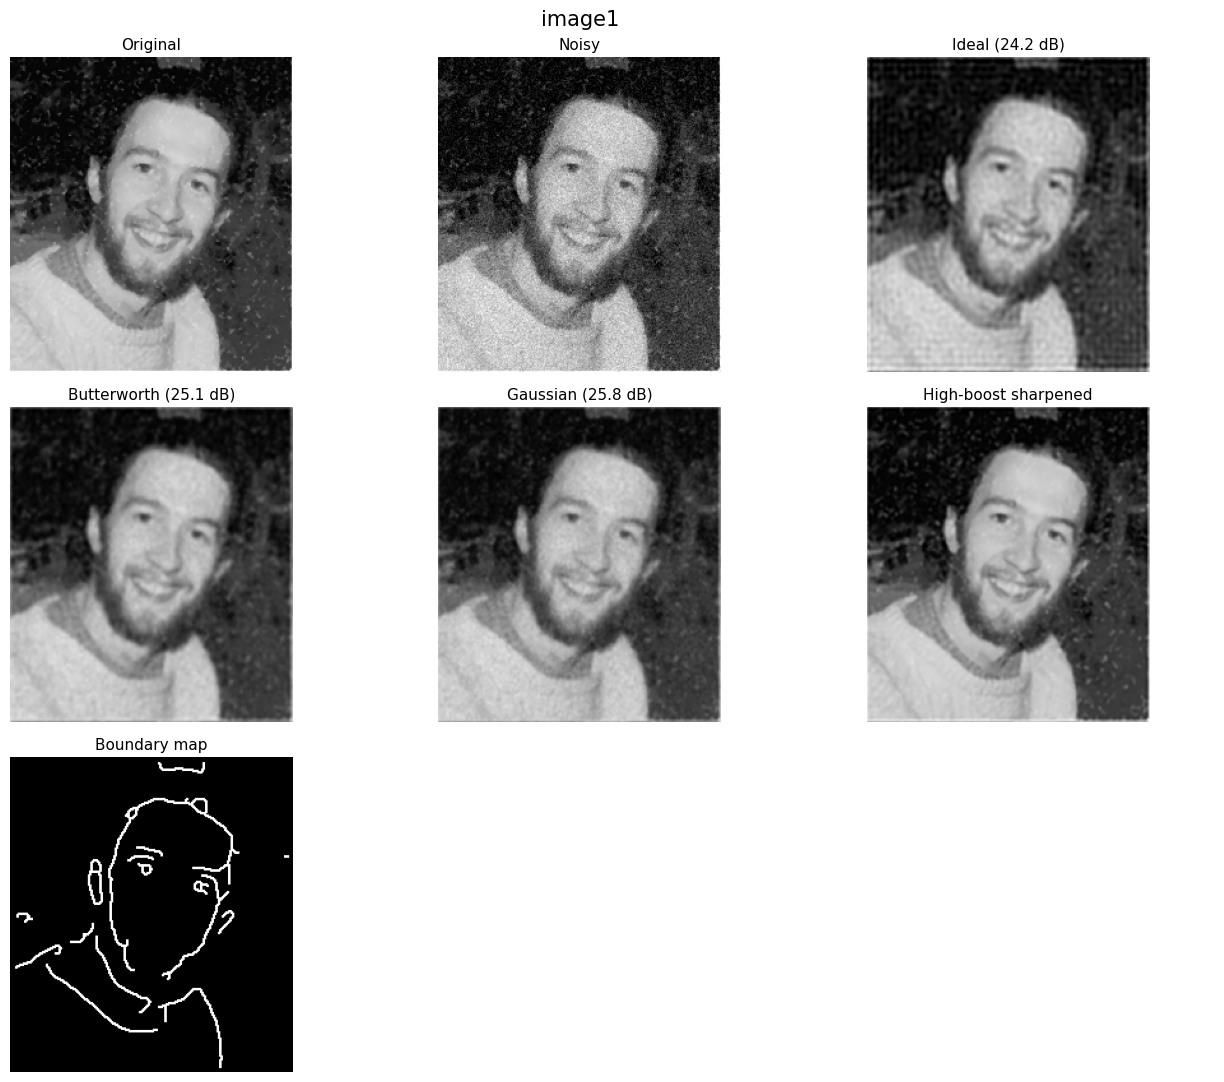

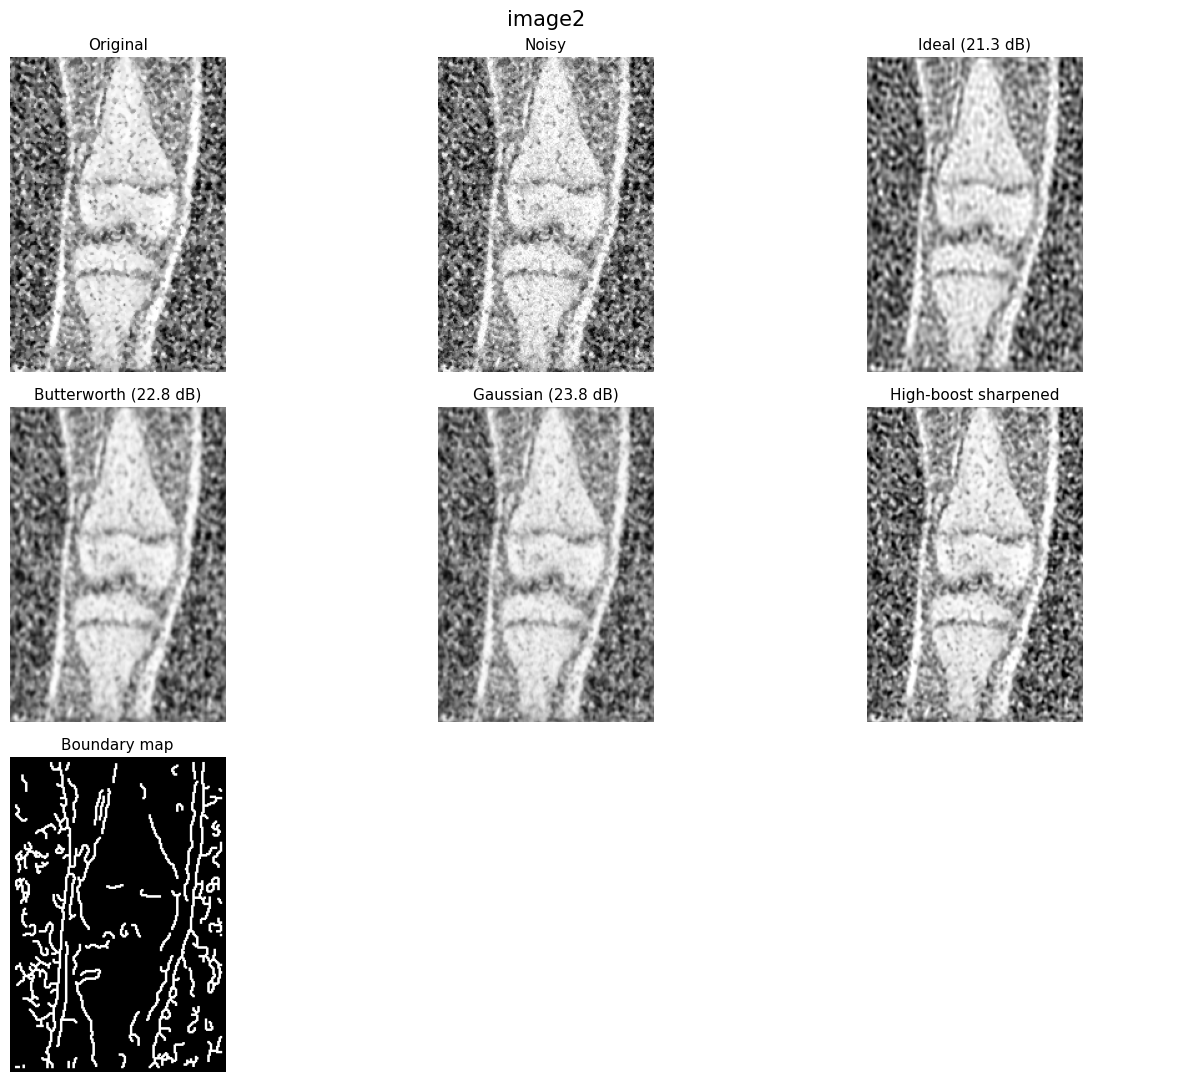

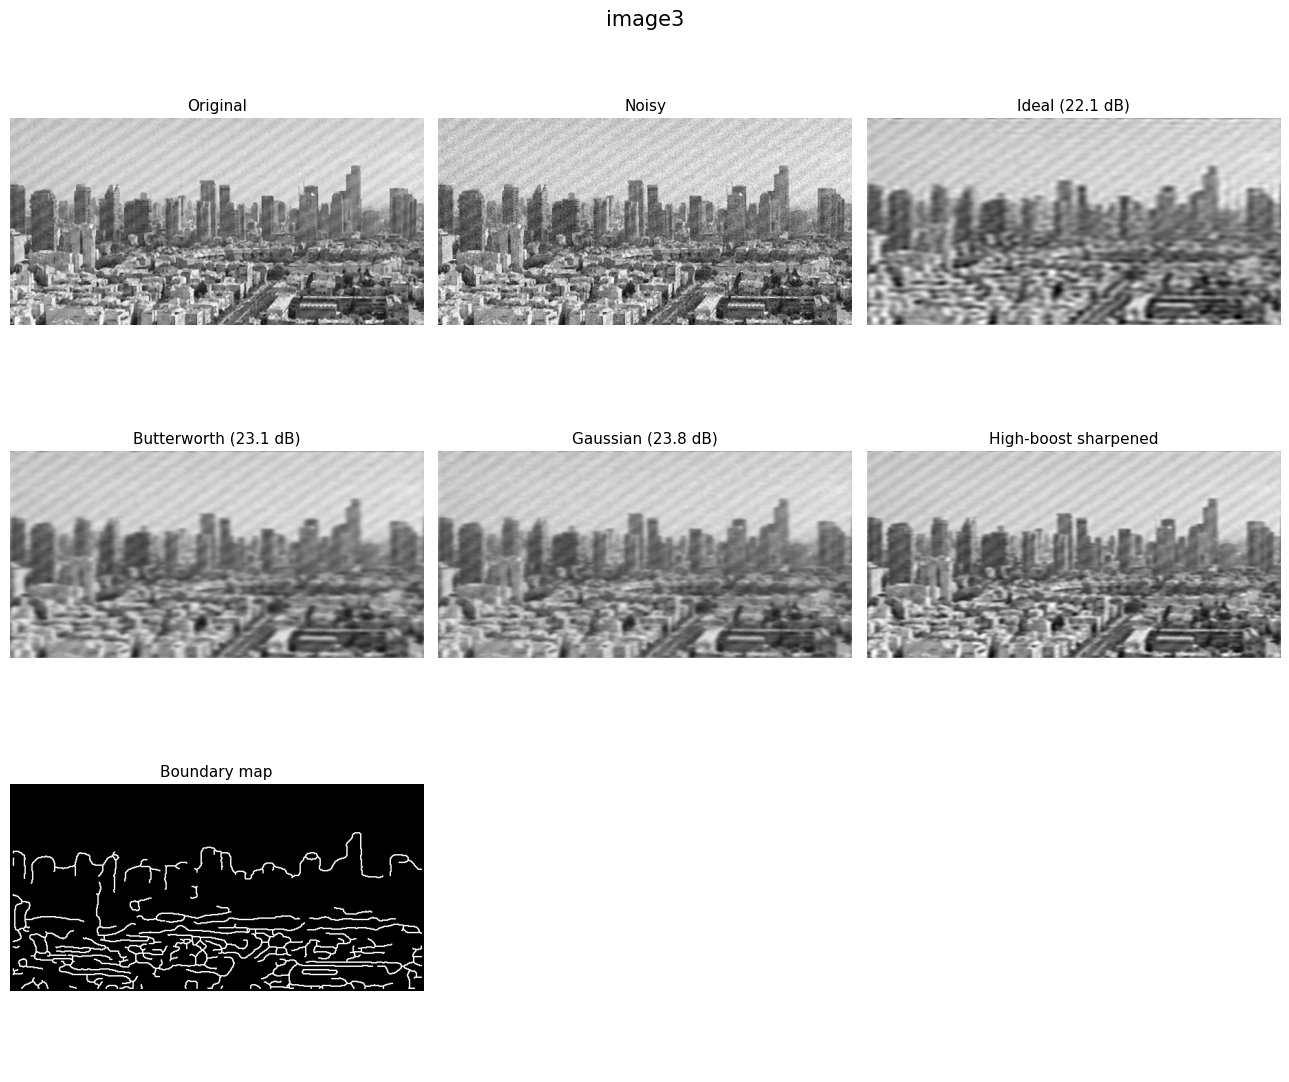

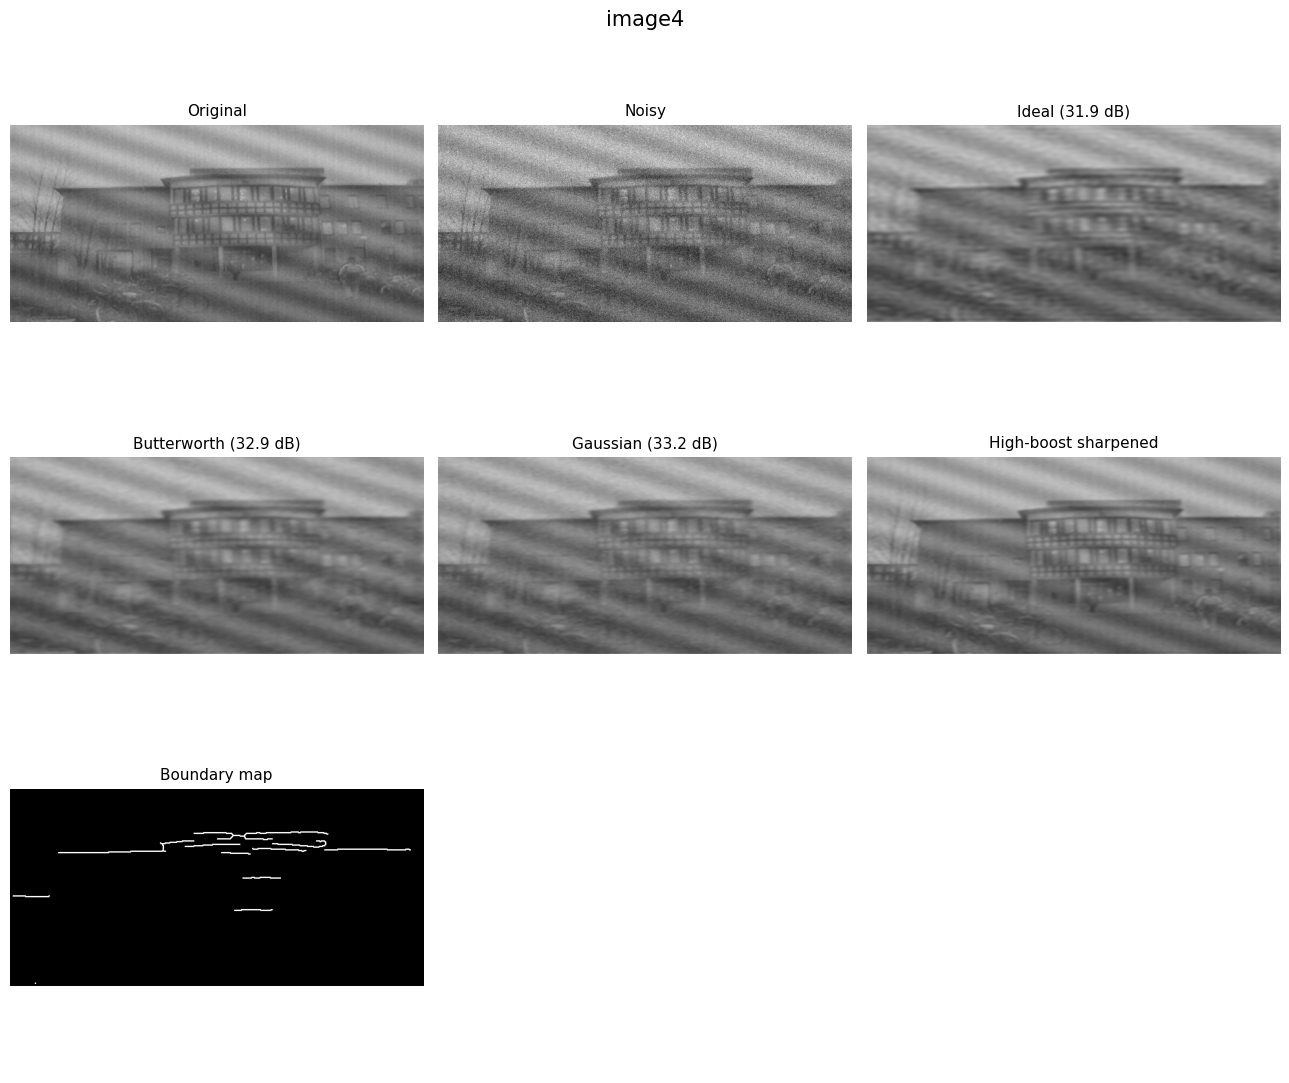

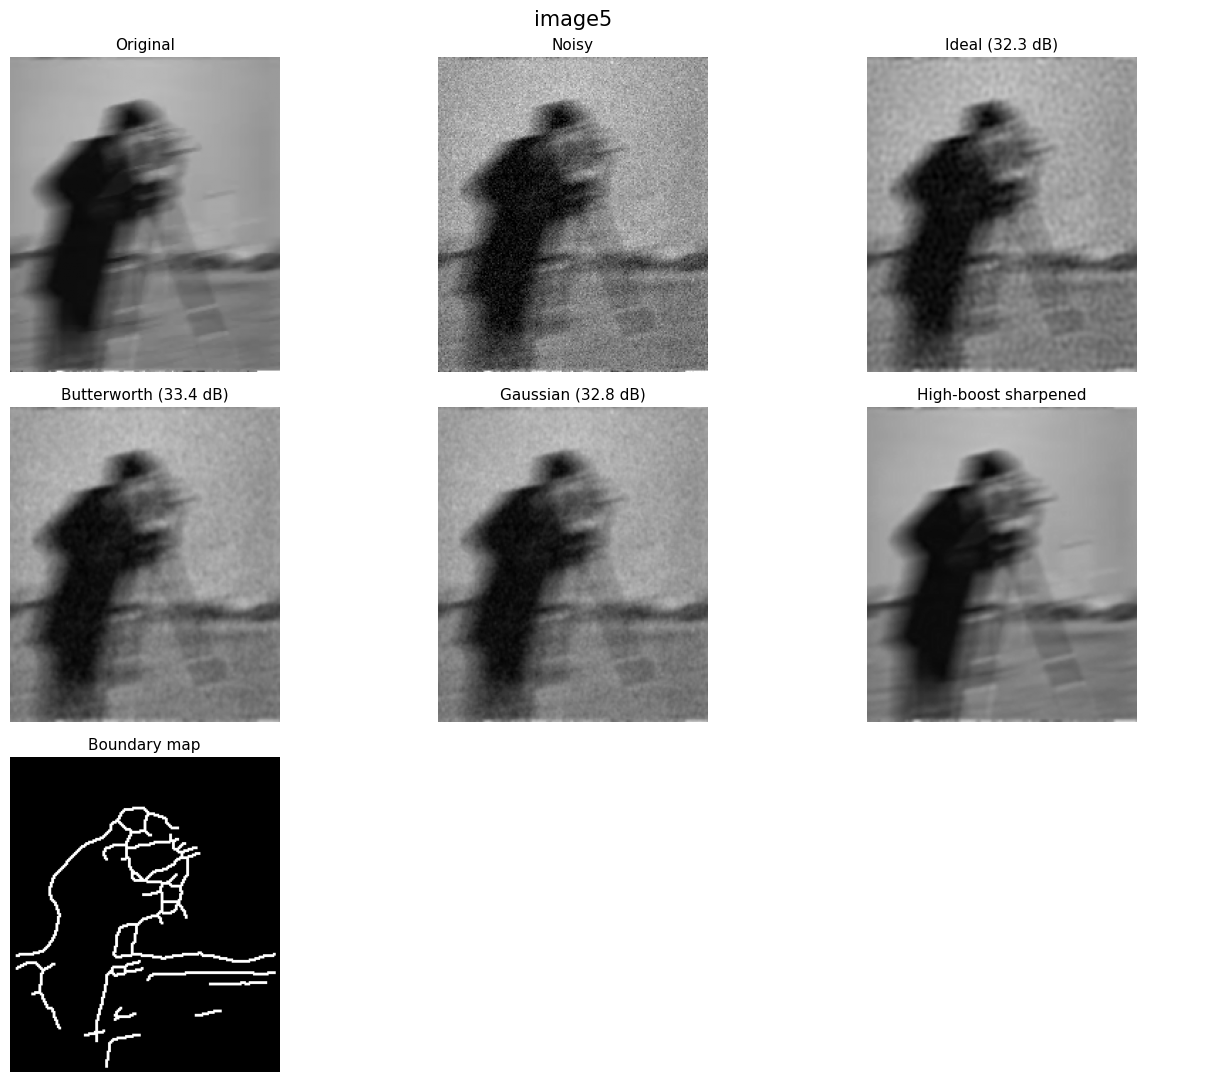

In [4]:
os.makedirs("results", exist_ok=True)
all_rows = []
for p in paths:
    im = cv2.imread(p, 0)
    if im is None: continue
    name = os.path.splitext(os.path.basename(p))[0]
    out, rows = process(im)
    all_rows += [(name, *r) for r in rows]
    fig, ax = plt.subplots(3, 3, figsize=(13, 11))
    for a in ax.ravel(): a.axis("off")
    for a, (t, x) in zip(ax.ravel(), out.items()):
        a.imshow(x, cmap="gray", vmin=0, vmax=255); a.set_title(t, fontsize=11)
    fig.suptitle(name, fontsize=15); plt.tight_layout()
    fig.savefig(f"results/{name}_figure.png", dpi=120); plt.show()
    cv2.imwrite(f"results/{name}_sharp.png", out["High-boost sharpened"])
    cv2.imwrite(f"results/{name}_boundary.png", out["Boundary map"])

## 4. Quantitative comparison

In [5]:
df = pd.DataFrame(all_rows, columns=["Image", "Filter", "PSNR (dB)", "SSIM"])
df.to_csv("results/metrics.csv", index=False)
display(df)
print("Best filter per image (by PSNR):")
display(df.loc[df.groupby("Image")["PSNR (dB)"].idxmax()].set_index("Image")[["Filter", "PSNR (dB)", "SSIM"]])
print("Average over all images:")
display(df.groupby("Filter")[["PSNR (dB)", "SSIM"]].mean().round(3))

,Image,Filter,PSNR (dB),SSIM
0,image1,Ideal,24.16,0.732
1,image1,Butterworth,25.13,0.808
2,image1,Gaussian,25.76,0.818
3,image2,Ideal,21.26,0.775
4,image2,Butterworth,22.78,0.834
5,image2,Gaussian,23.80,0.869
6,image3,Ideal,22.06,0.610
7,image3,Butterworth,23.11,0.690
8,image3,Gaussian,23.85,0.732
9,image4,Ideal,31.91,0.797


Best filter per image (by PSNR):


,Filter,PSNR (dB),SSIM
Image,,,
image1,Gaussian,25.76,0.818
image2,Gaussian,23.80,0.869
image3,Gaussian,23.85,0.732
image4,Gaussian,33.23,0.846
image5,Butterworth,33.37,0.843


Average over all images:


,PSNR (dB),SSIM
Filter,,
Butterworth,27.450,0.802
Gaussian,27.884,0.815
Ideal,26.338,0.743


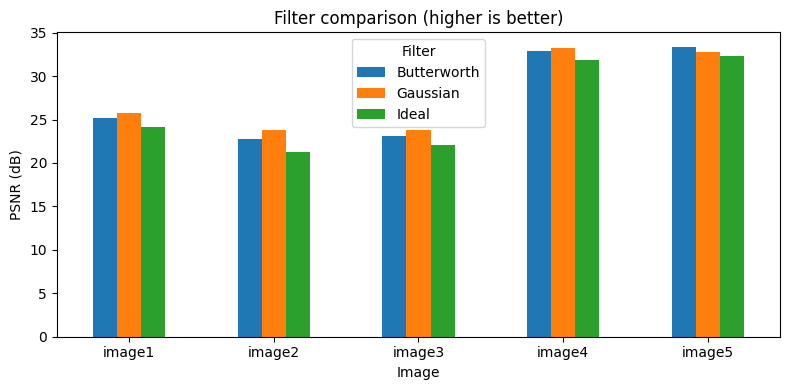

In [6]:
piv = df.pivot(index="Image", columns="Filter", values="PSNR (dB)")
piv.plot(kind="bar", figsize=(8, 4), rot=0); plt.ylabel("PSNR (dB)"); plt.title("Filter comparison (higher is better)")
plt.tight_layout(); plt.show()